# Statistical learning theory: what finite evidence can support

## 1. Introduction and learning objectives

A learning algorithm chooses a predictor using limited data. Statistical learning theory makes assumptions about that data and predictor family, then relates observed loss to future expected loss. The assumptions are part of the result. Counting experiments, obtaining a small training error or computing a confidence-looking number does not create a generalization guarantee automatically.

Derive a finite-class uniform bound and an empirical-risk-minimization comparison; distinguish approximation, estimation and optimization error; implement bounded probability and capacity calculations; and evaluate selection bias under controlled data. Connect these ideas to changing AI benchmarks and paper claims. This chapter supplies a concrete foundation, not a complete explanation of generalization in modern large neural networks.

**Prerequisites:** Stage 00 probability/expectation and stable logarithms; Stage 01 data splitting and generalization; the earlier Stage 02 algorithms, especially optimization limits in [trees](decision-trees.ipynb) and [SVMs](support-vector-machines-and-kernels.ipynb). Examples use binary zero-one loss. Required work is CPU-only, with fixed finite hypothesis tables and small generated samples.

## 2. Prerequisites and mathematical foundations

Let $Z_i=(X_i,Y_i)$ be iid observations from an unknown distribution $D$. A predictor $h$ has population risk $R(h)=\mathbb E_D[\ell(h,Z)]$ and empirical risk $\widehat R_S(h)=n^{-1}\sum_i\ell(h,Z_i)$. Here $0\le\ell\le1$. Zero-one classification loss satisfies this bound. Unrestricted squared error and log loss do not; applying the same inequality to them requires additional assumptions or an explicitly changed bounded loss.

For a **fixed predictor independent of the evaluation sample**, Hoeffding's inequality gives
$$P(|\widehat R_S(h)-R(h)|>\epsilon)\le2e^{-2n\epsilon^2}.$$
The probability is over repeated draws of $S$, with the predictor fixed. It is not a posterior probability that one realized fixed risk lies in an interval. When the same sample selects $h$, a fixed-predictor statement alone cannot be applied to the selected result without another argument.

For a finite class $\mathcal H$ with $M$ members fixed before drawing $S$, a union bound gives
$$P\left(\max_{h\in\mathcal H}|\widehat R_S(h)-R(h)|>\epsilon\right)\le2M e^{-2n\epsilon^2}.$$
Independence between hypotheses' errors is not required. The sample's iid assumption and a fixed eligible family still matter. Setting the right side to $\delta\in(0,1)$ gives
$$\epsilon(n,M,\delta)=\sqrt{\frac{\log2+\log M-\log\delta}{2n}}.$$
A radius larger than one is vacuous for this loss. Intersecting a risk interval with $[0,1]$ uses a known range; it does not make the original data or family assumptions true.

**Training/validation distinction:** $M$ fitted models produced from training data can be treated as fixed conditional on that training data when evaluated on an independent validation sample. Merely observing $M$ outputs of algorithms fitted on the **same evaluated sample** does not justify treating their full learning classes as having size $M$. A single memorizing program can select from an enormous family.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.07.01 — State the random object and eligible family

**Type:** Conceptual · **Answer:** Markdown

Compare evaluating one already frozen classifier on fresh iid observations, choosing the best of 20 frozen classifiers using that evaluation set, and training one flexible classifier on those same evaluation labels. Identify which finite-class count is justified in each case and which sample independence is missing.

**Expected outcome:** a precise evaluation population/sample, fixed-family explanation and a rejected naive algorithm-count argument.

**Your response to Exercise 02.07.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.01**

The number of fitted programs observed is not automatically the number of predictor functions their training procedures could select.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.01**

One frozen classifier permits a fixed-predictor bound with $M=1$. Selecting among 20 predictors fixed independently of the evaluation set permits a simultaneous $M=20$ bound, so selection is covered by that event. A flexible classifier trained on the same labels is selected using the evaluated sample; counting only its one output as $M=1$ ignores the possible data-dependent functions. A separate iid holdout can evaluate that trained classifier conditional on the training data. Dependence, changing populations or feedback from holdout labels require additional analysis rather than a different cosmetic count.

</details>

## 3. Theoretical development and worked examples

### Uniform control, optimization and the best model in a class

Suppose the uniform deviation event holds and a learner returns $\hat h$ with empirical optimization error at most $\tau\ge0$:
$$\widehat R_S(\hat h)\le\inf_{h\in\mathcal H}\widehat R_S(h)+\tau.$$
Then, for any comparison member $h$, $R(\hat h)\le\widehat R_S(\hat h)+\epsilon\le\widehat R_S(h)+\tau+\epsilon\le R(h)+\tau+2\epsilon$. Taking an infimum gives
$$R(\hat h)\le\inf_{h\in\mathcal H}R(h)+\tau+2\epsilon.$$
The two deviations explain the factor two. Let $R^*$ be the best risk over a larger declared target family (for zero-one prediction, the Bayes risk when appropriate). The term $\inf_{\mathcal H}R-R^*$ is approximation error; finite-sample deviations describe estimation; $\tau$ describes optimization in the **same empirical objective**. A dual gap for an SVM hinge objective cannot simply be inserted as optimization error for zero-one ERM. The objective and family must match.

If $\mathcal H$ contains the Bayes rule and exact empirical minimization is available, this comparison controls excess risk under its assumptions. If the family excludes a useful boundary or the greedy search misses a good tree, different terms matter. A bound may be conservative or vacuous on a small sample even when a particular predictor performs well. Failure to be informative is different from being mathematically false.

**Hand bound:** $n=200$, $M=20$, $\delta=.05$ gives $\epsilon=\sqrt{\log800/400}\approx.129273$. An observed error $.12$ yields the simultaneous risk range $[0,\min(1,.12+\epsilon)]$ with the lower endpoint also using the known range; more precisely the interval is $[\max(0,.12-\epsilon),\min(1,.12+\epsilon)]$. An exact ERM comparison adds $2\epsilon$ to the best risk in the fixed family. To target radius $.05$ with the same $M,\delta$, it suffices to take $n\ge\lceil\log800/[2(.05)^2]\rceil=1337$ under the same assumptions.

### Capacity for infinite classes: a small exact example

There are infinitely many real thresholds $h_t(x)=1[x\ge t]$. On $m$ distinct ordered real points, they produce only $m+1$ distinct label patterns: a block of zeros followed by ones, including both constant patterns. One point can receive either label, but two ordered points cannot receive pattern $(1,0)$ with this fixed orientation. Thus the VC dimension is one. If both orientations were allowed, it would be a different class.

An interval class $1[a\le x\le b]$, including an empty interval, has $1+m(m+1)/2$ patterns on ordered distinct points: choose an empty set or one contiguous block. Two points can be shattered, while three cannot realize $(1,0,1)$. Its VC dimension is two. Shattering means realizing **every** labeling on a set, and VC dimension is the largest size of **some** shattered set, not a guarantee about each arbitrary configuration in every domain.

The growth function counts the maximum patterns over sets of a given size. Sauer's counting result, for finite VC dimension $v$, gives $\Pi_{\mathcal H}(m)\le\sum_{j=0}^v\binom mj$ when $m\ge v$. Turning growth into a uniform population bound requires an additional probabilistic argument. **Do not substitute the number of patterns observed on one data set into the finite-class bound as if those were a fixed independent family.** Here we establish exact counting and VC intuition, not that invalid shortcut.

### Exact enumeration and empirical investigations

For a fixed binary predictor with known error probability $p$, the number of mistakes on $n$ iid observations is Binomial$(n,p)$. Summing $\binom nkp^k(1-p)^{n-k}$ over a specified deviation event gives its exact finite-model probability, evaluated with floating-point rounding in our small examples. This can check an inequality in a particular model, not prove a distribution-free theorem.

For another tractable model, let $X$ be uniform on $[0,1]$, true threshold $t_0$, and independently flip its binary label with probability $q\lt1/2$. For candidate $t\in[0,1]$,
$$R(h_t)=q+(1-2q)|t-t_0|.$$
The interval between thresholds has mass $|t-t_0|$; in that interval flipping exchanges correct/error probabilities, adding $1-2q$ per unit mass. Outside it the error remains $q$. Fixed threshold grids permit empirical learning experiments with known population risks instead of a large simulated test set.

### Exercise 02.07.02 — Derive the uniform and ERM comparisons

**Type:** Mathematical · **Answer:** Markdown

Use a union bound to derive the radius and reproduce the two-deviation comparison with empirical optimization tolerance $\tau$. State the bounded-loss, family and sampling assumptions at the exact steps where they are needed. Explain why a surrogate-objective optimizer's gap is not automatically the required $\tau$.

**Expected outcome:** the simultaneous event, factor two, additive optimization term and objective compatibility condition.

**Your response to Exercise 02.07.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.02**

Insert empirical risk twice, once for the selected member and once for a fixed comparison member, while remaining on one common uniform event.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.02**

Each fixed member has deviation probability at most $2e^{-2n\epsilon^2}$ under iid bounded observations. Summing those probabilities over the predeclared finite family gives $2M e^{-2n\epsilon^2}$ without requiring independence between members. Solving for failure level $\delta$ gives the displayed radius. On that event every member, including a data-selected one, obeys both deviation inequalities. The empirical optimization contract then yields $R(\hat h)\le R(h)+\tau+2\epsilon$ for every eligible $h$. The optimization contract must involve the same loss and family as the risks being compared; a hinge gap, a greedy split gain or a training log loss is not an empirical zero-one ERM gap by definition.

</details>

### Exercise 02.07.03 — Audit a bound and its sample budget

**Type:** Numerical · **Answer:** Markdown

Recompute the $n=200,M=20,\delta=.05$ example, the risk interval for empirical error $.12$, and the sample count for radius $.05$. Compare with $M=1$ using the same $n,\delta$. Does reducing the failure probability narrow or widen the interval?

**Expected outcome:** explicit logarithms and sample count 1337, a wider simultaneous bound for more candidates, and correct confidence-width direction.

**Your response to Exercise 02.07.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.03**

Compute log terms separately instead of constructing $2M/\delta$ for huge class counts.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.03**

The finite-family radius is $\sqrt{\log800/400}$, approximately $.129273$, giving an interval about $[0,.249273]$. At $M=1$ it is $\sqrt{\log40/400}\approx.0960323$. The required count is $\lceil6.6846117/.005\rceil=1337$. Smaller $\delta$ increases $-\log\delta$, so demanding a higher coverage guarantee widens this conservative interval at fixed sample size. An observed estimate is not made more precise just by requesting greater confidence.

</details>

## 4. Guided exercises

### Exercise 02.07.04 — Calculate finite-family radii and sample budgets

**Type:** Programming · **Answer:** Code

Implement `finite_class_radius(n, hypotheses, delta)` and `finite_class_sample_size(epsilon, hypotheses, delta)`. Validate positive integer counts, $0\lt\delta\lt1$, and positive finite target radius at most one. Preserve an uninformative radius rather than silently calling it precise. Use separated logarithms and test monotonicity.

**Expected outcome:** hand agreement, stated vacuity, increasing width with class count/confidence and inverse-square sample scaling.

In [ ]:
# Your code for Exercise 02.07.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.04**

The sample-size output is a ceiling. These numerical functions cannot verify independence or how the family was selected.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.04**

Counts are discrete; booleans are rejected. `math.log` supports large Python integer class counts without forming an overflowing ratio. Inputs and outputs still have finite floating-point precision. A range error is reported when the requested numerical budget cannot be represented.

~~~python
import math

def finite_class_log_term(hypotheses, delta):
    if isinstance(hypotheses,(bool,np.bool_)) or not isinstance(hypotheses,(int,np.integer)) or hypotheses < 1:
        raise ValueError('positive integer hypothesis count required')
    if not np.isfinite(delta) or not 0 < delta < 1:
        raise ValueError('failure probability in (0,1) required')
    return math.log(2)+math.log(int(hypotheses))-math.log(delta)

def finite_class_radius(n, hypotheses, delta):
    if isinstance(n,(bool,np.bool_)) or not isinstance(n,(int,np.integer)) or n < 1:
        raise ValueError('positive integer observation count required')
    return math.sqrt(finite_class_log_term(hypotheses,delta)/(2*int(n)))

def finite_class_sample_size(epsilon, hypotheses, delta):
    if not np.isfinite(epsilon) or not 0 < epsilon <= 1:
        raise ValueError('finite target radius in (0,1] required')
    denominator = 2*epsilon*epsilon
    if denominator == 0:
        raise FloatingPointError('requested radius is below numerical range')
    count = finite_class_log_term(hypotheses,delta)/denominator
    if not np.isfinite(count):
        raise FloatingPointError('required count is outside numerical range')
    return math.ceil(count)

assert finite_class_sample_size(.05,20,.05) == 1337
~~~

</details>

### Exercise 02.07.05 — Enumerate a finite binomial deviation probability

**Type:** Programming · **Answer:** Code

Implement `binomial_deviation_probability(n, p, epsilon)` for $1\le n\le200$, $p\in[0,1]$, and $\epsilon\in[0,1]$. Sum the exact finite-model masses with floating-point arithmetic for the strict event $|K/n-p|>\epsilon$. Check endpoints and compare to the capped Hoeffding upper bound. State numerical limitations at event boundaries and for extremely tiny probabilities.

**Expected outcome:** $1/8$ for $n=4,p=.5,\epsilon=.25$, valid endpoint behavior and a case where the conservative bound is vacuous.

In [ ]:
# Your code for Exercise 02.07.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.05**

Compare count deviations with $n\epsilon$ to avoid an unnecessary division per outcome; use `math.fsum` for the small nonnegative terms.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.05**

This is an exact model sum evaluated approximately, not a new statistical interval. We bound $n$ to keep the combinatorial exercise small. Floating-point event comparisons can be sensitive at nonrepresentable equality boundaries, so the independently checked hand case uses binary-exact quantities.

~~~python
def binomial_deviation_probability(n, p, epsilon):
    if isinstance(n,(bool,np.bool_)) or not isinstance(n,(int,np.integer)) or not 1 <= n <= 200:
        raise ValueError('integer count 1..200 required')
    if not np.isfinite(p) or not 0 <= p <= 1 or not np.isfinite(epsilon) or not 0 <= epsilon <= 1:
        raise ValueError('finite probability and deviation in [0,1] required')
    return math.fsum(math.comb(int(n),k)*p**k*(1-p)**(int(n)-k)
                     for k in range(int(n)+1) if abs(k-n*p) > n*epsilon)

assert binomial_deviation_probability(4,.5,.25) == .125
~~~

</details>

## 5. Implementation challenges

Use finite tables to make class membership, capacity and selection visible. The pattern enumeration below is a counting investigation. The later learning experiment uses a **separately predeclared fixed grid**, so its finite-family bound does not depend on candidate thresholds constructed from evaluated labels or sample points.

### Exercise 02.07.06 — Enumerate threshold and interval label patterns

**Type:** Programming · **Answer:** Code

Implement `threshold_patterns(points)` and `interval_patterns(points)` for at most 64 finite scalar points. Return unique binary patterns in original point-column order, allowing repeated points. Verify exact counts on distinct points and exhibit shattering/non-shattering examples. Do not interpret the returned data-dependent pattern count as a ready-made population guarantee.

**Expected outcome:** $m+1$ and $1+m(m+1)/2$ counts, duplicate consistency, VC dimensions one/two and a clear counting scope.

In [ ]:
# Your code for Exercise 02.07.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.06**

Rank the distinct points. Thresholds choose a rank cut; intervals choose a consecutive block or the empty pattern. No floating midpoint is necessary.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.06**

These functions represent the class's restrictions to the supplied finite set. Constant patterns are included, repeated coordinates always share a label, and no label-fitting algorithm is hidden in this counting operation.

~~~python
def capacity_points(points):
    x = np.asarray(points,dtype=float)
    if x.ndim != 1 or not 1 <= len(x) <= 64 or not np.isfinite(x).all():
        raise ValueError('1..64 finite scalar points required')
    _, ranks = np.unique(x,return_inverse=True)
    return ranks,int(ranks.max()+1)

def threshold_patterns(points):
    ranks,m = capacity_points(points)
    return (ranks[None,:] >= np.arange(m+1)[:,None]).astype(np.uint8)

def interval_patterns(points):
    ranks,m = capacity_points(points)
    patterns = [np.zeros(len(ranks),dtype=np.uint8)]
    for left in range(m):
        for right in range(left,m):
            patterns.append(((ranks >= left)&(ranks <= right)).astype(np.uint8))
    return np.array(patterns)

assert threshold_patterns([0.,1.,2.]).shape == (4,3)
assert interval_patterns([0.,1.,2.]).shape == (7,3)
~~~

</details>

### Exercise 02.07.07 — Select a member of a fixed finite table

**Type:** Programming · **Answer:** Code

Implement `select_fixed_hypothesis(predictions, labels)` for binary prediction rows and compatible binary labels. Return the first minimum-error index and every empirical error. Also implement `threshold_population_risk` for the stated uniform-input/independent-label-noise model. Independently check both against enumerated tiny cases. The code cannot enforce that the table was fixed before the evaluated sample.

**Expected outcome:** exact losses, deterministic ties, an analytical risk curve and an explicit assumption boundary.

In [ ]:
# Your code for Exercise 02.07.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.07**

Each row is a different eligible predictor. Prediction columns correspond to the same observations for all members.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.07**

The population-risk formula is valid for thresholds in $[0,1]$, a uniform input and independent label flips at a rate below $.5$. It is not a generic risk estimator for arbitrary datasets. The selection function checks shapes/values, not statistical provenance.

~~~python
def select_fixed_hypothesis(predictions, labels):
    predictions = np.asarray(predictions); y = np.asarray(labels)
    if predictions.ndim != 2 or min(predictions.shape) == 0 or y.shape != (predictions.shape[1],) or not np.isin(predictions,[0,1]).all() or not np.isin(y,[0,1]).all():
        raise ValueError('nonempty binary prediction table and compatible labels required')
    errors = np.mean(predictions != y[None,:],axis=1)
    return int(np.argmin(errors)),errors

def threshold_population_risk(thresholds, truth=.4, noise=.1):
    t = np.asarray(thresholds,dtype=float)
    if not np.isfinite(t).all() or np.any((t < 0)|(t > 1)) or not np.isfinite(truth) or not 0 <= truth <= 1 or not np.isfinite(noise) or not 0 <= noise < .5:
        raise ValueError('thresholds/truth in [0,1] and independent flip rate in [0,.5) required')
    return noise+(1-2*noise)*np.abs(t-truth)

assert select_fixed_hypothesis([[0,0],[1,1]],[0,1])[0] == 0
assert np.allclose(threshold_population_risk([.4,.5]),[.1,.18])
~~~

</details>

### Exercise 02.07.08 — Prove the capacity and population-risk examples

**Type:** Mathematical · **Answer:** Markdown

Show the exact pattern counts and VC arguments for fixed-orientation thresholds and intervals. Derive the noisy-threshold risk formula using the input mass on which two thresholds disagree. Explain why a smaller empirical error need not imply smaller population error when the family is enlarged.

**Expected outcome:** counting and shattering arguments, an exact model-specific risk identity and a selection-versus-approximation distinction.

**Your response to Exercise 02.07.08**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.08**

An interval selects a contiguous block of ordered points. The symmetric difference between two threshold regions has length $|t-t_0|$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.08**

Thresholds have one rank cut among $m+1$ possibilities. Intervals have $m(m+1)/2$ nonempty consecutive blocks plus the empty pattern. Thresholds can label one point both ways but cannot label two ordered points $(1,0)$; intervals shatter two but cannot realize $(1,0,1)$ on three ordered points. Under uniform inputs, the threshold disagreement region has probability $|t-t_0|$. There the error changes from $q$ to $1-q$, yielding $q+(1-2q)|t-t_0|$. Enlarging a family can reduce its best attainable population risk but also offer more opportunities to fit sample fluctuations. A smaller empirical minimum alone resolves neither effect.

</details>

## 6. Experiments and visualizations

The first panel plots the theorem's analytical radius for fixed candidate counts, not measured learning curves. The second plots the **known** population risk of the specified noisy-threshold model. The experiments then create observations and evaluate actual selection outcomes separately.

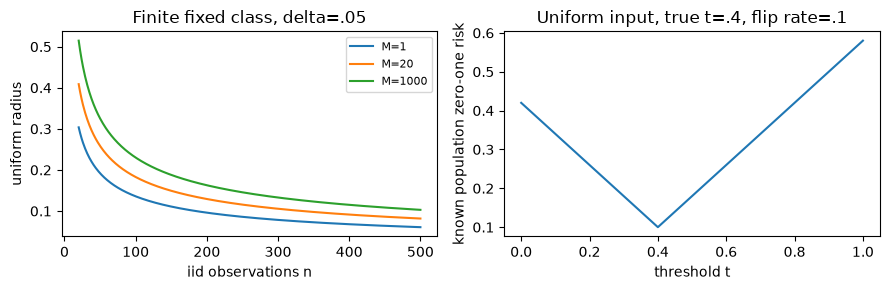

In [2]:
fig, axes = plt.subplots(1,2,figsize=(9,3))
demo_n = np.arange(20,501)
demo_radii = {}
for M in (1,20,1000):
    demo_radii[M] = np.sqrt((np.log(2)+np.log(M)-np.log(.05))/(2*demo_n))
    axes[0].plot(demo_n,demo_radii[M],label=f'M={M}')
axes[0].set(xlabel='iid observations n',ylabel='uniform radius',title='Finite fixed class, delta=.05')
axes[0].legend(fontsize=8)
demo_thresholds = np.linspace(0,1,101)
demo_population_risk = .1+.8*np.abs(demo_thresholds-.4)
axes[1].plot(demo_thresholds,demo_population_risk)
axes[1].set(xlabel='threshold t',ylabel='known population zero-one risk',title='Uniform input, true t=.4, flip rate=.1')
fig.tight_layout(); plt.show()

### Exercise 02.07.09 — Observe selection bias with known equal true risks

**Type:** Experimental · **Answer:** Code

Before drawing datasets, fix a binary hypothesis table with 128 rows on a 32-value input universe using seed 233. For 200 independent trials with seed 234, draw 64 iid training inputs and 128 fresh validation inputs uniformly from that universe; all labels are independent fair coins. Compare selecting among the first $M\in\{1,16,128\}$ fixed members. Report mean selected training/validation errors, their trial variation, and uniform-bound violation counts at $\delta=.1$. Every true risk is exactly $.5$. Do not present an observed zero violation count as proof of the theorem or zero failure probability.

**Expected outcome:** actual repeated-sampling records, known true risks, fixed nested families and a finite Monte Carlo limitation.

In [ ]:
# Your code for Exercise 02.07.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.09**

Use identical datasets across candidate counts in each trial. The union event concerns the worst deviation of all eligible members, not only the winner.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.09**

This depends on selection/radius references. The table is frozen independently of every evaluated dataset, so a finite-family calculation is applicable. Validation remains fresh after selection. Report trial standard deviations as descriptive repeated-sampling variability; they are not automatically confidence intervals for a selected published result.

~~~python
demo_table = np.random.default_rng(233).integers(0,2,size=(128,32),dtype=np.uint8)
demo_rng = np.random.default_rng(234)
demo_selection_records = {M: [] for M in (1,16,128)}
for trial in range(200):
    train_x = demo_rng.integers(0,32,size=64); train_y = demo_rng.integers(0,2,size=64)
    valid_x = demo_rng.integers(0,32,size=128); valid_y = demo_rng.integers(0,2,size=128)
    for M, records in demo_selection_records.items():
        selected,errors = select_fixed_hypothesis(demo_table[:M,train_x],train_y)
        validation = np.mean(demo_table[selected,valid_x] != valid_y)
        violated = bool(np.max(np.abs(errors-.5)) > finite_class_radius(64,M,.1))
        records.append((float(errors[selected]),float(validation),violated))
for M, records in demo_selection_records.items():
    values = np.array(records,dtype=float)
    print('Measured null selection:',M,'means',values[:,:2].mean(axis=0),
          'trial SD',values[:,:2].std(axis=0,ddof=1),'violations',int(values[:,2].sum()),'/ 200')
~~~

</details>

### Exercise 02.07.10 — Compare a conservative bound with known learning risks

**Type:** Experimental · **Answer:** Code

Use a fixed threshold grid `linspace(0,1,21)` chosen before observations, true threshold $.4$ and independent flip rate $.1$. With seed 235, run 100 independent datasets for each $n\in\{20,80,320\}$. Select by empirical error and calculate the selected **exact model population risk**. Report median/90th-percentile excess over the best grid member, the analytical $2\epsilon$ comparison at $\delta=.1$, and uniform-deviation violation counts. Record workload/time and explain conservative or vacuous cases.

**Expected outcome:** measured learning-risk summaries with exact-model risks, no simulated test-set noise, and separate theory/Monte Carlo claims.

In [ ]:
# Your code for Exercise 02.07.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.10**

The eligible grid is fixed; do not replace it with sample-derived threshold midpoints and keep the same finite-$M$ argument.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.10**

This depends on selection, risk and radius references. The known risk formula makes excess calculation independent of an extra finite test set. Quantiles over these 100 training samples describe this experiment, not an all-distributions guarantee. The radius is a sufficient conservative bound and need not track median performance closely.

~~~python
from time import perf_counter

demo_grid = np.linspace(0,1,21); demo_true_risks = threshold_population_risk(demo_grid)
demo_rng = np.random.default_rng(235); demo_learning_records = []
for n in (20,80,320):
    started = perf_counter(); excess = []; violations = 0
    radius = finite_class_radius(n,len(demo_grid),.1)
    for trial in range(100):
        X = demo_rng.uniform(size=n)
        y = (X >= .4).astype(int); y ^= demo_rng.binomial(1,.1,size=n)
        selected,errors = select_fixed_hypothesis((X[None,:] >= demo_grid[:,None]).astype(int),y)
        excess.append(float(demo_true_risks[selected]-demo_true_risks.min()))
        violations += int(np.max(np.abs(errors-demo_true_risks)) > radius)
    demo_learning_records.append((n,np.quantile(excess,[.5,.9]),2*radius,violations,perf_counter()-started))
print('Measured threshold excess-risk records:',demo_learning_records)
~~~

</details>

## 7. Interpretation and critical analysis

### Bounded primary-source study

Read [CS229 Learning Theory, §3, The case of finite H](https://cs229.stanford.edu/summer2020/cs229-notes4.pdf). Audit the transition from one fixed member to a simultaneous event. Translate notation, identify what is fixed before sampling, and test one small finite-model probability. The study does not reproduce a full VC uniform-convergence proof or claim that one coarse bound explains current neural-network generalization.

### Exercise 02.07.11 — Audit a benchmark guarantee under adaptive reuse

**Type:** Critical · **Answer:** Markdown

A team repeatedly changes prompts, features or training recipes after inspecting one benchmark, then reports its best score with a fixed-predictor Hoeffding interval using $M=1$. Explain which assumption is unsupported. Propose an evaluation that preserves a clear final claim, considering contaminated/duplicated data, a changed target population and uncertainty across tasks.

**Expected outcome:** an explicit selection/independence diagnosis, a primary-source connection and a bounded replacement protocol.

**Your response to Exercise 02.07.11**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.11**

Calling a set a test set does not preserve its role after repeated feedback. A count of visible final model files does not quantify every adaptive choice.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.11**

The selected predictor depends on feedback from the evaluated labels, so a fixed-predictor independence argument with $M=1$ is unsupported. A predeclared finite independent family can receive a simultaneous argument, but arbitrary adaptive exploration is not captured by counting only final files. Use training/internal validation for development, lock the evaluation protocol and then use a fresh final sample representing the declared population. Check overlap/duplicates and report what is known about training contamination; separate per-task performance and sampling units rather than assuming independent benchmark questions automatically. A population shift changes the target risk. The source's finite-family transition identifies the required selection control; neither the theorem nor a fresh average alone establishes broad capability across every future task.

</details>

### Exercise 02.07.12 — Separate parameter count, optimization and empirical evidence

**Type:** Critical · **Answer:** Markdown

A paper fits a large network well, observes good validation performance, and says that its number of parameters is its VC dimension and therefore explains the measured error. Identify the unsupported steps. Describe a bounded report combining assumptions, empirical results and mathematical facts without inventing a generalization theorem.

**Expected outcome:** family/architecture and loss distinctions, appropriate uncertainty, and a supported experimental claim with limitations.

**Your response to Exercise 02.07.12**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.12**

Capacity depends on the function class, not just a raw parameter counter. A numerical optimizer's certificate concerns its own objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.12**

Parameter count alone does not define VC dimension for every parameterized family; architecture, parameter restrictions and the classification rule matter. The observed run is a finite experiment, while a theorem needs a specified loss, family, sampling assumptions and a valid bound. A good optimizer or small surrogate loss does not supply missing statistical assumptions. Report the declared datasets/splits, selection effort, baseline, seeds, metrics and uncertainty, then state the mathematical identities or bounds that actually apply. An ablation can support a bounded effect under controlled conditions. It cannot manufacture a capacity theorem or universal explanation for modern networks from one measured success.

</details>

## 8. Review questions and knowledge checks

### Exercise 02.07.13 — Compare an exact event with a conservative inequality

**Type:** Numerical · **Answer:** Markdown

For $n=4,p=.5,\epsilon=.25$, enumerate the strict deviation event and its binomial probability. Compare it to $\min(1,2e^{-2n\epsilon^2})$. With three distinct ordered inputs, list a labeling impossible for fixed-orientation thresholds and one impossible for intervals. Explain why these examples check specific claims but do not prove all stated probability inequalities.

**Expected outcome:** event $K\in\{0,4\}$, probability $1/8$, capped bound one, and valid missing patterns.

**Your response to Exercise 02.07.13**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.13**

Strict deviation excludes counts at distance exactly one from the mean count two.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.13**

Only counts zero and four differ from the expected count two by more than one. Each has mass $1/16$, giving $1/8$. The uncapped Hoeffding expression is $2e^{-1/2}>1$, so the probability upper bound is one and is uninformative here. Pattern $(1,0,0)$ is impossible for the fixed increasing threshold orientation; pattern $(1,0,1)$ is impossible for an interval. Enumeration verifies these finite-model calculations and class restrictions. It does not replace the distribution-free concentration proof or justify a shortcut from sample pattern counts to a population bound.

</details>

### Exercise 02.07.14 — Present a statistical-learning mastery gate

**Type:** Conceptual · **Answer:** Markdown

Explain fixed versus selected predictors, iid bounded losses, simultaneous control, ERM's factor two, objective-compatible optimization error, growth/shattering, and validation reuse. Point to an independent binomial check, pattern enumeration, known-risk experiment and a claim still unsupported.

**Expected outcome:** explain/implement/verify/evaluate evidence and a clear boundary between exact mathematics, finite calculations and empirical conclusions.

**Your response to Exercise 02.07.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.07.14**

For each claim, name the random sample, eligible family, target risk and selection protocol.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.07.14**

A fixed-predictor bound assumes independence from the evaluated sample. A predeclared finite family admits simultaneous control and covers later member selection on one common event. The ERM comparison uses two deviation terms plus an optimization tolerance for the same empirical objective. Capacity examples count achievable labelings; a VC-to-risk theorem needs additional probability reasoning. Exact binomial sums and class enumeration check finite contracts, while known-risk repeated experiments measure a declared learner/model. Reused validation, dependent observations, unbounded losses, surrogate mismatch and shifting populations require additional arguments. Passing these checks does not certify arbitrary future AI capability or explain all neural-network generalization.

</details>

## 9. Summary and next learning steps

Statistical guarantees are statements with a sample, population, family, loss and selection protocol. Make each explicit before calculating a bound. Exact toy models reveal where numerical checks apply, while repeated experiments show a bounded learner's behavior without proving a universal claim. These habits are essential when following rapidly changing AI benchmarks and research results.

Before advancing, submit the concentration/ERM derivations, manual bound/probability/capacity functions, independently verified hand cases, measured selection and known-risk studies, and the bounded source audit. Next is the classical benchmark capstone: compare manual algorithms on shared data and budgets, with honest model selection, optimizer diagnostics and one final evaluation. Return to the [stage guide](README.md) or [full learning path](../../README.md); readiness remains partial until the integrated capstone is authored and validated.